# MT2503 Multivariate Calculus: Computing Project (Semester 1 of 2023/24)

## Instructions

#### Before starting the project
There are two helper worksheets associated with this project. These look at those parts of Python's *SymPy* and *Matplotlib* libraries that are required for this project. You should work through these first before attempting the project.  The exercises within those worksheets are not assessed (and solutions are available); they are designed to help you familiarise yourself with the relevant commands.

#### Submitting your project
You should upload your work to the relevant MySaint area as a single file by **5pm on Thursday 16 November 2023**. In order to do this, you will need to download the file from this server using `Download as>Notebook` in the `File` menu. The file **must** be downloaded as a Notebook. Your project must be self-contained such that it works when run in sequence (from top to bottom) by the marker. Please **validate** the project before submitting it (see below). When you are ready to submit your project, the process is therefore (in order): validate your project, download the project as a Notebook, and upload this Notebook to MySaint.

The project is worth 15% of your final grade in the module.  There are 25 marks available for the project.

#### Getting help
Help is available from staff in your computing lab session for each of Weeks 7-10 of the semester.  Make sure to use these well and do not leave all your questions to Week 10 (there are only so many queries we can answer in the hour.)


#### Validation
You will see a number of code cells in the notebook with the comment `# VALIDATION CELL` at the top. You do not need to, and should not, make changes to these cells. Running one of these cells will perform some simple checks on the format of your work (for example, checking whether you have defined the variables a question specifies). If a problem is detected an error will be produced giving you some feedback; if there is no detected problem there will be no output. These cells **do not** test if your answer is actually correct. You can run all of the validation cells by clicking the "Validate" button on the menu bar, but be aware that the validation for questions you have not attempted yet will automatically fail. Please ensure using the "Validate" button that your code passes all of the tests before submitting your project.

#### Other comments
For each question some empty cells have been inserted. Please don't read anything into the number. You can add or delete cells as you wish. 

Some questions have been broken down into lettered parts for clarity, but you can answer each question in the cells below the question statement (you don't need to say which corresponds to which part(s)).

## Project:  Using Python for understanding a function of two variables.

The aim of this project is to show how Python (paticularly via tools in *SymPy* and *Matplotlib*) may be used to help understand functions of two variables. 

We will define a function, illustrate it using surface and contour plots, and locate every stationary point of the function, identifying the nature of each such point. Finally we'll look at maxima and minima subject to a constraint.

The function we will be working with is $$ f(x,y)= (x^3+y^3-xy) \cdot e^{-x^2-y^2}. $$

### Question 1
We'll start by defining our function in Python and making some initial plots to help see how the function is varying with $x$ and $y$.

&nbsp;  

(a) Load the relevant packages, and define `x` and `y` as *SymPy* symbols. Use these to define the function `f`. 

(b) Use `matplotlib` to make both a surface plot and a contour plot of $f(x,y)$, choosing an appropriate range for both independent variables so that the main features of the function are shown on your plots.

<p style='text-align:right;'> <b> [4 Marks] </b> </p>

In [127]:
#importing relevant packages
import sympy as sym
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline
sym.init_printing()

In [128]:
#defining x and y as SymPy symbols and defining the function f
x,y = sym.symbols('x, y', real=True)
f = (x**3 + y**3 -x*y)*sym.exp(-x**2 -y**2)

In [129]:
#translating the SymPy expression into a Python function 
f2 = sym.lambdify([x,y], f, 'numpy')

Text(0.5, 0.92, 'Surface plot of f(x,y)')

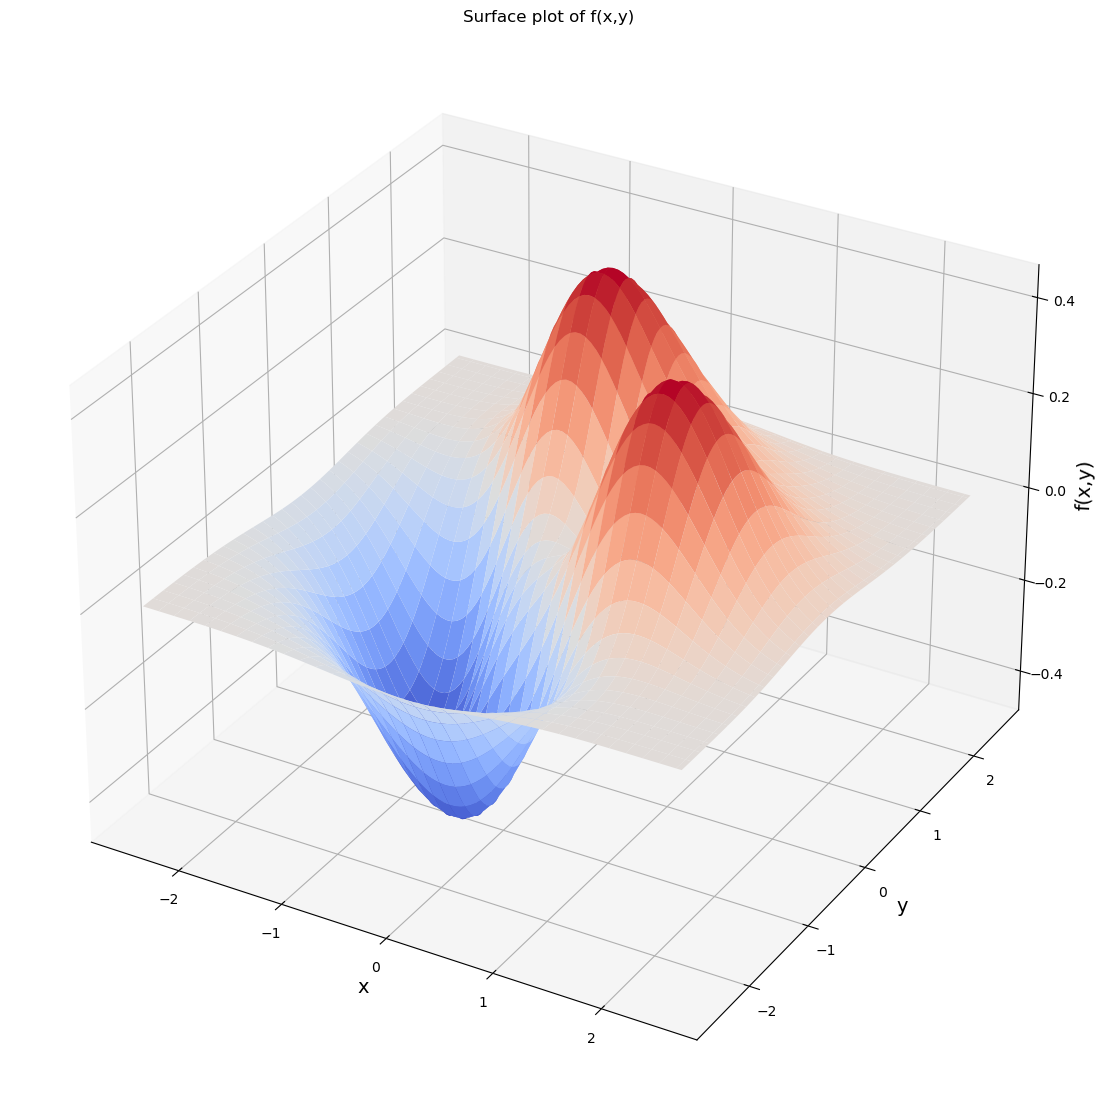

In [130]:
#SURFACE PLOT OF f(x,y)

# defining points in the x and y directions
xp = np.arange(-2.5,2.55,0.05)
yp = np.arange(-2.5,2.55,0.05)

#making a grid of points
X,Y = np.meshgrid(xp,yp)

#defining function
Z=f2(X,Y)

#figure and subplot initialization
fig = plt.figure(1,figsize=(14,14))
ax = fig.add_subplot(111, projection='3d')

#plotting surface
ax.plot_surface(X,Y,Z, cmap='coolwarm')

#drawing labels
ax.set_xlabel('x',fontsize=14)
ax.set_ylabel('y',fontsize=14)
ax.set_zlabel('f(x,y)',fontsize=14);
ax.set_title("Surface plot of f(x,y)")

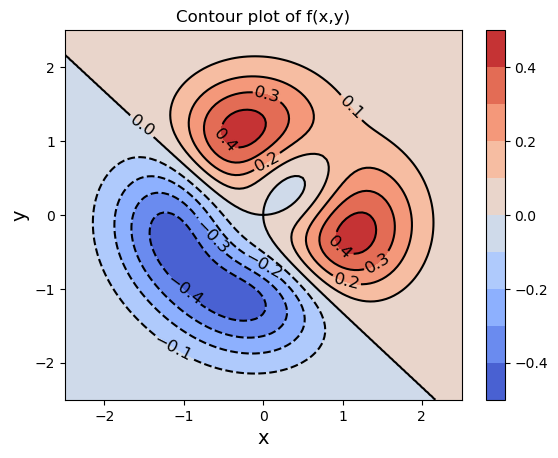

In [131]:
#CONTOUR PLOT OF f(x,y)

#defining points in x and y directions
xp = np.arange(-2.5, 2.55, 0.05)
yp = np.arange(-2.5,2.55,0.05)

#making grid of points
X,Y = np.meshgrid(xp,yp)

#defining function
Z=f2(X,Y)

#figure and subplot initialization
fig = plt.figure(1)
ax = fig.add_subplot(111)

#plotting contours
B = ax.contour(X,Y,Z, levels=10, colors='k')

#drawing labels
ax.clabel(B, fontsize=12)
ax.set_xlabel('x', fontsize=14)
ax.set_ylabel('y', fontsize=14)
ax.set_title("Contour plot of f(x,y)")

#filling contour plot 
C = ax.contourf(X,Y,Z, levels=10, cmap = plt.cm.coolwarm)
fig.colorbar(C)

In [132]:
# VALIDATION CELL
# Cells like this contain some validation.
# If an error is produced, you need to fix something in your code.
# If no error is produced, this is *NOT* a guarantee you have correctly answered the question.
# Do not modify these cells.

from unittest import TestCase
import sympy as sym
nbg_tc = TestCase()

# f, x, and y should be defined
for var in ['f', 'x', 'y']:
    if not var in globals():
        raise NotImplementedError(f"{var} has not been defined in Question 1")

# x and y should be symbols
for var in [x, y]:
    nbg_tc.assertIsInstance(var,
                            sym.core.symbol.Symbol,
                            msg = f"{var} should be a SymPy symbol, not a {type(var).__name__}")

### Question 2
In this question we will try to find stationary points of $f(x,y)$, using inbuilt solvers in *SymPy*.

&nbsp;  

(a) Use *Sympy* to find the two first partial derivatives of $f$, $\frac{\partial f}{\partial x}$ and $\frac{\partial f}{\partial y}$, and store these in variables called `fx` and `fy`.

Stationary points are locations where the following system of equations is satisfied:

$$\frac{\partial f}{\partial x}=0, \ \  \frac{\partial f}{\partial y}=0.$$ 
  

(b) Use the `nonlinsolve` command to try to solve the system of equations $\{f_x=0, f_y=0\}$, storing any solutions obtained in a list called `SOLS1`. Make sure your list contains real valued solutions correct to 4 significant figures, and remove any complex solutions from your list.
<p style='text-align:right;'> <b> [3 Marks] </b> </p> 

In [133]:
fx = sym.diff(f,x)
fx

In [134]:
fy = sym.diff(f,y)
fy

In [135]:
results = list((sym.nonlinsolve([fx, fy], [x,y]) & (sym.Reals ** 2)).args)
SOLS1=[]
for a,b in results:
    SOLS1.append((a.evalf(4),b.evalf(4)))
print(SOLS1)

[(0, 0), (1.000, 1.000), (0.3090, 0.3090), (-0.8090, -0.8090), (-0.4864, -1.059), (-1.059, -0.4864), (1.163, -0.2591), (-0.2591, 1.163)]


In [136]:
# VALIDATION CELL
from unittest import TestCase
import sympy as sym
nbg_tc = TestCase()

# fx and fy should be defined
for var in ['fx', 'fy']:
    if not var in globals():
        raise NotImplementedError(f"{var} has not been defined in Question 1.2")

# fx and fy should be expressions
for var in [fx, fy]:
    nbg_tc.assertIsInstance(var,
                            sym.core.Expr,
                            msg = f"{var} should be a SymPy expression, not a {type(var).__name__}")


In [137]:
# VALIDATION CELL
from unittest import TestCase
import sympy as sym
nbg_tc = TestCase()

# SOLS1 should be defined
if not 'SOLS1' in globals():
    raise NotImplementedError("SOLS1 has not been defined in Question 2")
    
# SOLS1 should be a list
nbg_tc.assertIsInstance(SOLS1, list, 
                        msg = f"SOLS1 should be a list, not a {type(SOLS1).__name__}")

# SOLS1 should be nonempty
nbg_tc.assertTrue(len(SOLS1) > 0, msg = "SOLS1 is empty")

# Each solution should be a tuple of length 2
for nbg_sol in SOLS1:
    nbg_tc.assertIsInstance(nbg_sol,
                            (tuple, list, sym.core.containers.Tuple), 
                            msg = "each individual solution should be a tuple or a list")
    nbg_tc.assertEqual(len(nbg_sol), 2,
                 msg = "each individual solution should have length 2")


### Question 3
In this question we will take those stationary points identified in Question 2 and use algebraic techniques to determine the nature of each point.

&nbsp;  

(a) Use *SymPy* to demonstrate that the mixed partial derivatives $\frac{\partial^2 f}{\partial x \partial y}$ and $\frac{\partial^2 f}{\partial y \partial x}$ are, as expected, equal for this function.

(b) Use *SymPy* to find the discriminant of $f(x,y)$ and store this as `Delta`. 

(c) Use the discriminant (`Delta`) and other appropriate algebraic derivative tests as necessary to classify each stationary point you found in Question 2 as either a maximum, minimum, or a saddle point. 

To store your results create a list called `SOLS1_TYPES` where each entry has format `[x,y,'type']` (e.g. `[5,-7,'saddle']`).    
<p style='text-align:right;'> <b> [4 Marks] </b> </p>

In [138]:
#(a)
#if the result is 0 then fxy = fyx as expected:
(sym.diff(f, x, y) - sym.diff(f, y, x)) == 0

True

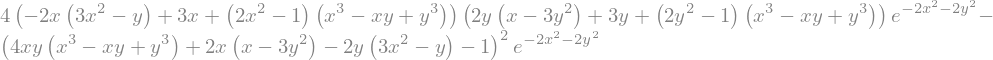

In [139]:
#(b)
Delta = sym.diff(f,x,x)*sym.diff(f,y,y) - sym.diff(f,x,y)**2
Delta

In [140]:
SOLS1_TYPES = []

for x0,y0 in SOLS1:
    
    stationary_type=''
    if Delta.evalf(subs={x:x0, y:y0}) < 0:
        stationary_type = 'saddle'
        
    elif Delta.evalf(subs={x:x0, y:y0}) > 0:
        
        if sym.diff(f,x,x).evalf(subs={x:x0, y:y0}) < 0:
            stationary_type = 'maximum'
        elif sym.diff(f,x,x).evalf(subs={x:x0, y:y0}) > 0:
            stationary_type = 'minimum'
            
    SOLS1_TYPES.append([x0,y0,stationary_type])

print(SOLS1_TYPES)

[[0, 0, 'saddle'], [1.000, 1.000, 'saddle'], [0.3090, 0.3090, 'minimum'], [-0.8090, -0.8090, 'saddle'], [-0.4864, -1.059, 'minimum'], [-1.059, -0.4864, 'minimum'], [1.163, -0.2591, 'maximum'], [-0.2591, 1.163, 'maximum']]


In [141]:
# VALIDATION CELL
from unittest import TestCase
import sympy as sym
nbg_tc = TestCase()

# Delta should be defined
if not 'Delta' in globals():
    raise NotImplementedError("Delta has not been defined in Question 1.3")

# Delta should be a sympy expression
nbg_tc.assertIsInstance(Delta,
                        sym.core.Expr,
                        msg = f"Delta should be a SymPy expression, not a {type(Delta).__name__}")


In [142]:
# VALIDATION CELL
from unittest import TestCase
import sympy as sym
nbg_tc = TestCase()

# SOLS1_TYPES should be defined
if not 'SOLS1_TYPES' in globals():
    raise NotImplementedError("SOLS1_TYPES has not been defined in Question 3")

# SOLS1_TYPES should be a list
nbg_tc.assertIsInstance(SOLS1_TYPES,
                        list,
                        msg = f"SOLS1_TYPES should be a list, not a {type(SOLS1_TYPES).__name__}")

# SOLS1_TYPES should not be empty
nbg_tc.assertTrue(len(SOLS1_TYPES) > 0, "SOLS1_TYPES is empty")

# Each entry of SOLS1_TYPES should be a list of length 3
for nbg_sol in SOLS1_TYPES:
    nbg_tc.assertIsInstance(nbg_sol,
                            (tuple, list), 
                            msg = "each entry of SOLS1_TYPES should be a tuple or a list")
    nbg_tc.assertEqual(len(nbg_sol),
                       3,
                       msg = "each entry of SOLS1_TYPES should have length 3")
    
    # The third value in each entry should be one of "minimum", "maximum", or "saddle"
    nbg_tc.assertIn(nbg_sol[2].lower(),
                    ["maximum", "minimum", "saddle"],
                    f"{nbg_sol[2]} should be one of 'maximum', 'minimum', or 'saddle'")


### Question 4

The discriminant test used in Question 3 was shown in lectures to have been obtained from the Taylor series representation of a function about a stationary point $(x_0,y_0)$. The aim of this question is to use plots to show how a 2D Taylor series taken about a point at $(x_0,y_0)$ **locally** approximates the function near to that point. 

Recall that the second degree Taylor approximation to $f(x,y)$ about $(x_0,y_0)$ is given by

$$f(x,y) = f(x_0,y_0) + f_x(x_0,y_0)(x-x_0) + f_y(x_0,y_0)(y-y_0) + \frac{1}{2} \left( f_{xx}(x_0,y_0)(x-x_0)^2 + 2 f_{xy}(x_0,y_0)(x-x_0)(y-y_0) + f_{yy}(y-y_0)^2 \right).$$


&nbsp;    &nbsp;  

(a) Take the two stationary points found in Question 2 that are closest to the origin. For each stationary point make a contour plot of $f(x,y)$ on the square region of width $0.2$ centered at the stationary point. For example, if a stationary point was at $(1.0,2.0)$ then you would make a contour plot of $f(x,y)$ with $x \in [0.9,1.1]$ and $y \in [1.9,2.1]$.

(b) Use *SymPy* to find the second degree Taylor approximation of $f(x,y)$ at each of your two points. Call these quadratics `Q1` and `Q2`, with `Q1` being the one corresponding to the point closest to the origin.

(c) Show contour plots of $f(x,y)$ and `Q1` on the same image, on a range $x \in [x_0-\delta, x_0+\delta]$, $y \in [y_0-\delta, y_0+\delta]$ for $\delta = 0.5, 0.25$, and $0.05$ (so making three plots in total). Repeat the procedure for the second stationary point.  Briefly discuss your observations in the provided text cell.

 <p style='text-align:right;'> <b> [5 Marks] </b> </p>

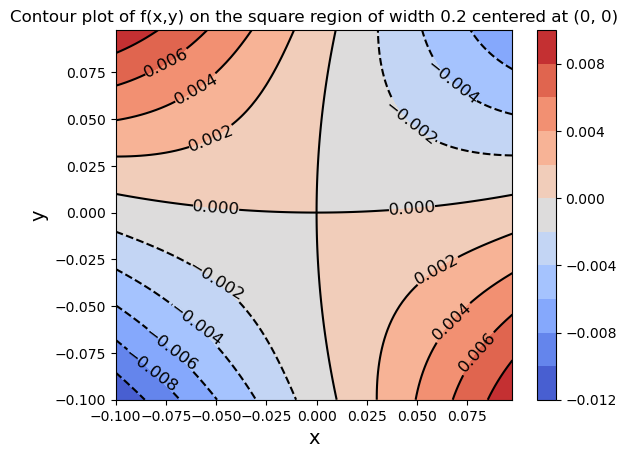

In [143]:
#(a)
#two stationary points in Question 2 closest to the origin are:
stationary_points = [(0, 0), (0.3090, 0.3090)]

#CONTOUR PLOT OF f(x,y) on range x in [-0.1, 0.1] and y in [-0.1, 0.1] 

#defining points in x and y directions
xp = np.arange(-0.1, 0.1, 0.0025)
yp = np.arange(-0.1, 0.1, 0.0025)

#making grid of points
X,Y = np.meshgrid(xp,yp)

#defining function
Z = f2(X,Y)

#figure and subplot initialization
fig = plt.figure(1)
ax = fig.add_subplot(111)

#plotting contours
B = ax.contour(X,Y,Z, levels=10, colors='k')

#drawing labels
ax.clabel(B, fontsize=12)
ax.set_xlabel('x', fontsize=14)
ax.set_ylabel('y', fontsize=14)
ax.set_title("Contour plot of f(x,y) on the square region of width 0.2 centered at (0, 0)")

#filling contour plot 
C = ax.contourf(X,Y,Z, levels=10, cmap = plt.cm.coolwarm)
fig.colorbar(C)

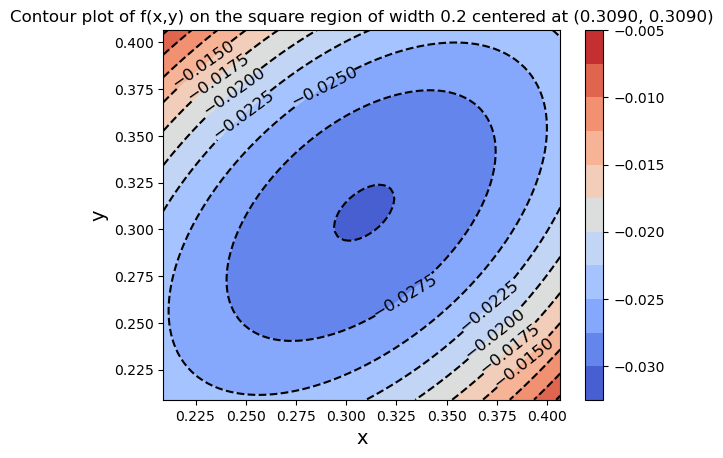

In [144]:
#(a)
#CONTOUR PLOT OF f(x,y) on range x in [0.2090, 0.4090] and y in [0.2090, 0.4090] 

#defining points in x and y directions
xp = np.arange(0.2090, 0.4090, 0.0025)
yp = np.arange(0.2090, 0.4090, 0.0025)

#making grid of points
X,Y = np.meshgrid(xp,yp)

#defining function
Z = f2(X,Y)

#figure and subplot initialization
fig = plt.figure(1)
ax = fig.add_subplot(111)

#plotting contours
B = ax.contour(X,Y,Z, levels=10, colors='k')

#drawing labels
ax.clabel(B, fontsize=12)
ax.set_xlabel('x', fontsize=14)
ax.set_ylabel('y', fontsize=14)
ax.set_title("Contour plot of f(x,y) on the square region of width 0.2 centered at (0.3090, 0.3090)")

#filling contour plot 
C = ax.contourf(X,Y,Z, levels=10, cmap = plt.cm.coolwarm)
fig.colorbar(C)

In [145]:
#(b)
fxx = sym.diff(f, x, x)
fyy = sym.diff(f, y, y)
fxy = sym.diff(f, x, y)
# Second degree Taylor approximation of f evaluated at (0,0)
Q1 = f.evalf(subs={x: 0, y: 0}) + (x*fx + y*fy) + 0.5*((x**2)*fxx + 2*x*y*fxy + (y**2)*fyy)

# Second degree Taylor approximation of f evaluated at (0.3090, 0.3090)
Q2 = f.evalf(subs={x: 0.3090, y: 0.3090}) + ((x-0.3090)*fx + (y-0.3090)*fy) + 0.5*(((x-0.3090)**2)*fxx + 2*(x-0.3090)*(y-0.3090)*fxy + ((y-0.3090)**2)*fyy)

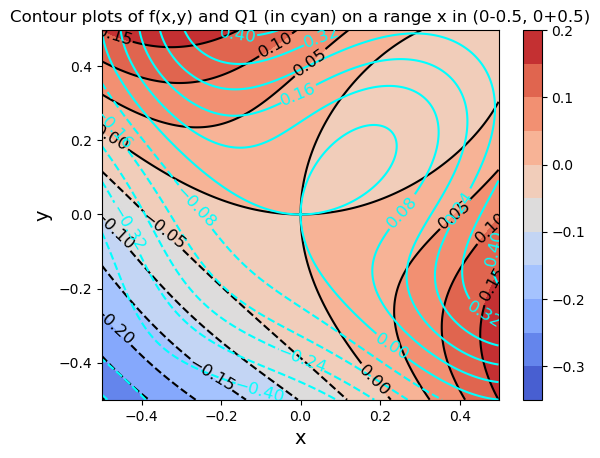

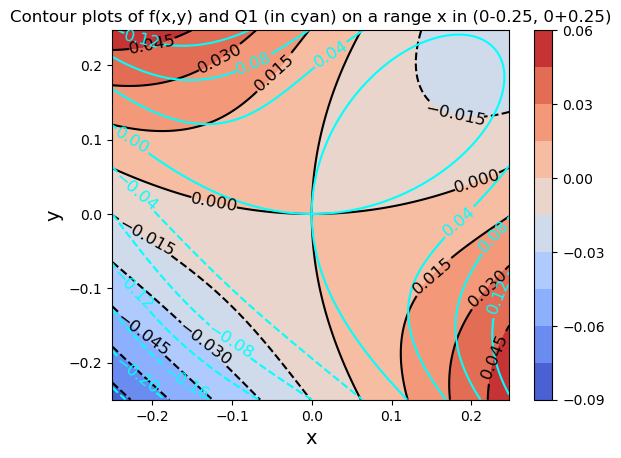

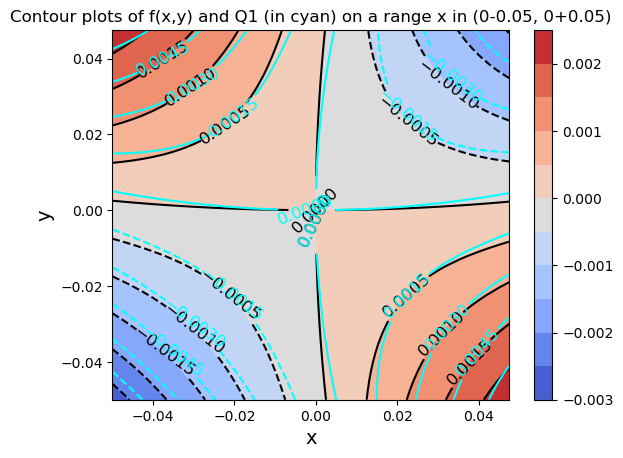

In [146]:
#need to do the contour plot (c)

sigma = [0.5, 0.25, 0.05]
    #CONTOUR PLOT OF f(x,y) on range x in [-0.1, 0.1] and y in [-0.1, 0.1]

q1 = sym.lambdify([x,y], Q1, 'numpy')
#defining points in x and y directions
xp1 = np.arange(0-sigma[0], 0+sigma[0], 0.0025)
yp1 = np.arange(0-sigma[0], 0+sigma[0], 0.0025)
xp2 = np.arange(0-sigma[1], 0+sigma[1], 0.0025)
yp2 = np.arange(0-sigma[1], 0+sigma[1], 0.0025)
xp3 = np.arange(0-sigma[2], 0+sigma[2], 0.0025)
yp3 = np.arange(0-sigma[2], 0+sigma[2], 0.0025)

#making grid of points
X1,Y1 = np.meshgrid(xp1,yp1)
X2,Y2 = np.meshgrid(xp2,yp2)
X3,Y3 = np.meshgrid(xp3,yp3)

#defining function
Z1 = f2(X1,Y1)
Z2 = f2(X2,Y2)
Z3 = f2(X3,Y3)

#figure and subplot initialization
fig1 = plt.figure(1)
ax1 = fig1.add_subplot(111)
fig2 = plt.figure(2)
ax2 = fig2.add_subplot(111)
fig3 = plt.figure(3)
ax3 = fig3.add_subplot(111)

#plotting contours
B1 = ax1.contour(X1,Y1,Z1, levels=10, colors='k')
B2 = ax2.contour(X2,Y2,Z2, levels=10, colors='k')
B3 = ax3.contour(X3,Y3,Z3, levels=10, colors='k')
D1 = ax1.contour(X1,Y1,q1(X1,Y1), levels=10, colors='aqua')
D2 = ax2.contour(X2,Y2,q1(X2,Y2), levels=10, colors='aqua')
D3 = ax3.contour(X3,Y3,q1(X3,Y3), levels=10, colors='aqua')

#drawing labels
ax1.clabel(B1, fontsize=12)
ax1.clabel(D1, fontsize=12)
ax1.set_xlabel('x', fontsize=14)
ax1.set_ylabel('y', fontsize=14)
ax1.set_title("Contour plots of f(x,y) and Q1 (in cyan) on a range x in (0-0.5, 0+0.5)")

ax2.clabel(B2, fontsize=12)
ax2.clabel(D2, fontsize=12)
ax2.set_xlabel('x', fontsize=14)
ax2.set_ylabel('y', fontsize=14)
ax2.set_title("Contour plots of f(x,y) and Q1 (in cyan) on a range x in (0-0.25, 0+0.25)")

ax3.clabel(B3, fontsize=12)
ax3.clabel(D3, fontsize=12)
ax3.set_xlabel('x', fontsize=14)
ax3.set_ylabel('y', fontsize=14)
ax3.set_title("Contour plots of f(x,y) and Q1 (in cyan) on a range x in (0-0.05, 0+0.05)")

#filling contour plot 
C1 = ax1.contourf(X1,Y1,Z1, levels=10, cmap = plt.cm.coolwarm)
C2 = ax2.contourf(X2,Y2,Z2, levels=10, cmap = plt.cm.coolwarm)
C3 = ax3.contourf(X3,Y3,Z3, levels=10, cmap = plt.cm.coolwarm)
fig1.colorbar(C1)
fig2.colorbar(C2)
fig3.colorbar(C3)

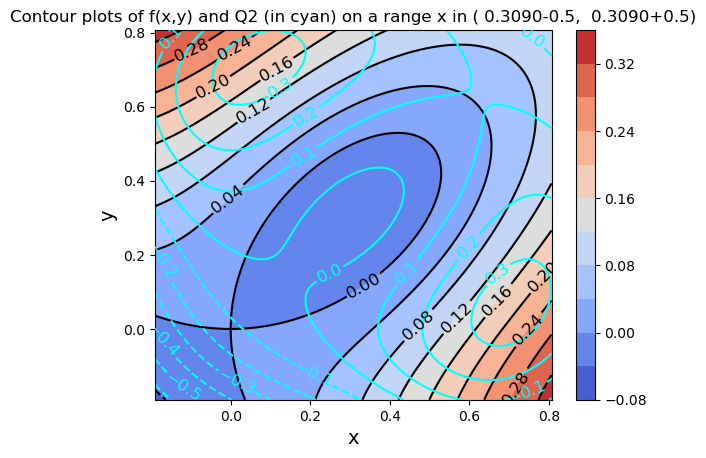

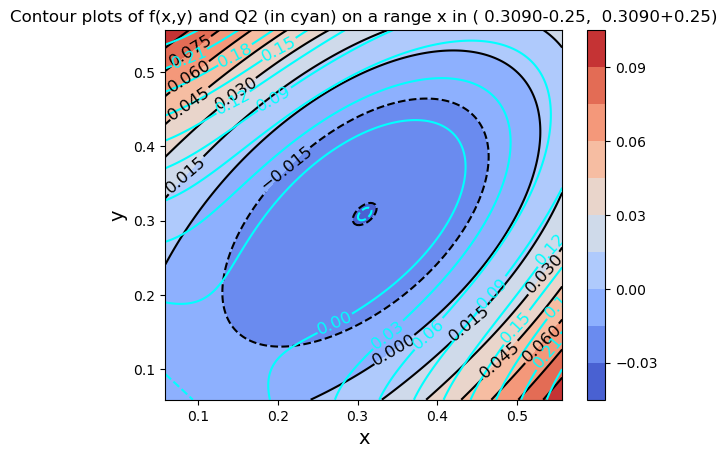

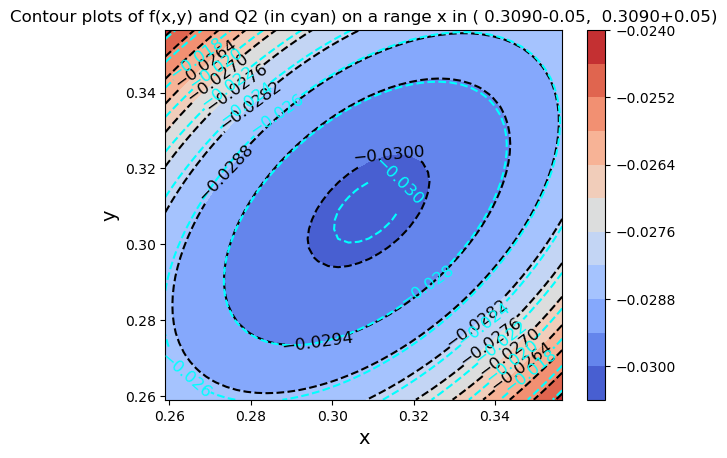

In [147]:
#need to do the contour plot (c)

sigma = [0.5, 0.25, 0.05]
q2 = sym.lambdify([x,y], Q2, 'numpy')
#defining points in x and y directions
xp1 = np.arange(0.3090-sigma[0], 0.3090+sigma[0], 0.0025)
yp1 = np.arange(0.3090-sigma[0], 0.3090+sigma[0], 0.0025)
xp2 = np.arange(0.3090-sigma[1], 0.3090+sigma[1], 0.0025)
yp2 = np.arange(0.3090-sigma[1], 0.3090+sigma[1], 0.0025)
xp3 = np.arange(0.3090-sigma[2], 0.3090+sigma[2], 0.0025)
yp3 = np.arange(0.3090-sigma[2], 0.3090+sigma[2], 0.0025)

#making grid of points
X1,Y1 = np.meshgrid(xp1,yp1)
X2,Y2 = np.meshgrid(xp2,yp2)
X3,Y3 = np.meshgrid(xp3,yp3)

#defining function
Z1 = f2(X1,Y1)
Z2 = f2(X2,Y2)
Z3 = f2(X3,Y3)

#figure and subplot initialization
fig1 = plt.figure(1)
ax1 = fig1.add_subplot(111)
fig2 = plt.figure(2)
ax2 = fig2.add_subplot(111)
fig3 = plt.figure(3)
ax3 = fig3.add_subplot(111)

#plotting contours
B1 = ax1.contour(X1,Y1,Z1, levels=10, colors='k')
B2 = ax2.contour(X2,Y2,Z2, levels=10, colors='k')
B3 = ax3.contour(X3,Y3,Z3, levels=10, colors='k')
D1 = ax1.contour(X1,Y1,q2(X1,Y1), levels=10, colors='aqua')
D2 = ax2.contour(X2,Y2,q2(X2,Y2), levels=10, colors='aqua')
D3 = ax3.contour(X3,Y3,q2(X3,Y3), levels=10, colors='aqua')

#drawing labels
ax1.clabel(B1, fontsize=12)
ax1.clabel(D1, fontsize=12)
ax1.set_xlabel('x', fontsize=14)
ax1.set_ylabel('y', fontsize=14)
ax1.set_title("Contour plots of f(x,y) and Q2 (in cyan) on a range x in ( 0.3090-0.5,  0.3090+0.5)")

ax2.clabel(B2, fontsize=12)
ax2.clabel(D2, fontsize=12)
ax2.set_xlabel('x', fontsize=14)
ax2.set_ylabel('y', fontsize=14)
ax2.set_title("Contour plots of f(x,y) and Q2 (in cyan) on a range x in ( 0.3090-0.25,  0.3090+0.25)")

ax3.clabel(B3, fontsize=12)
ax3.clabel(D3, fontsize=12)
ax3.set_xlabel('x', fontsize=14)
ax3.set_ylabel('y', fontsize=14)
ax3.set_title("Contour plots of f(x,y) and Q2 (in cyan) on a range x in ( 0.3090-0.05,  0.3090+0.05)")

#filling contour plot 
C1 = ax1.contourf(X1,Y1,Z1, levels=10, cmap = plt.cm.coolwarm)
C2 = ax2.contourf(X2,Y2,Z2, levels=10, cmap = plt.cm.coolwarm)
C3 = ax3.contourf(X3,Y3,Z3, levels=10, cmap = plt.cm.coolwarm)
fig1.colorbar(C1)
fig2.colorbar(C2)
fig3.colorbar(C3)

From the 6 contour plots of f(x,y) and Q1 or Q2 we observe that the 2D Taylor series local approximation of the function f is more and more precise as we get closer to the value (0,0) for Q1 and (0.3090, 0.3090) for Q2 (i.e., for s = 0.05) but as we move away from the the point at which we approximate the function, this becomes less and less precise.

For both points as we diminish the size of the range of x and y (diminish δ), we get closer to the point at which the second degree polynomial (Q1 for (0,0) or Q2 for (0.3090, 0.3090) and the approximation as expected gets closer to the real value of f(x,y) around these points. We can conclude that for δ of 0.05 both approximations Q1 and Q2 are very accurate and follow the contours of f(x,y) while for δ of 0.5 these are not really accurate and does not fully follow the contours of f(x,y).

In [148]:
# VALIDATION CELL
from unittest import TestCase
import sympy as sym
import numpy as np
nbg_tc = TestCase()

# Q1 and Q2 should be defined
for var in ['Q1', 'Q2']:
    if not var in globals():
        raise NotImplementedError(f"{var} has not been defined in Question 4")

# Q1 and Q2 should be SymPy expressions
for var in [Q1, Q2]:
    nbg_tc.assertIsInstance(var,
                            sym.core.Expr,
                            msg = f"{var} should be a SymPy expression, not a {type(var).__name__}")


### Question 5

Generate one figure that clearly illustrates your findings from the above (i.e. make a plot that shows the function, marks each stationary point and indicates the nature of each point).   
<p style='text-align:right;'> <b> [2 Marks] </b> </p> 

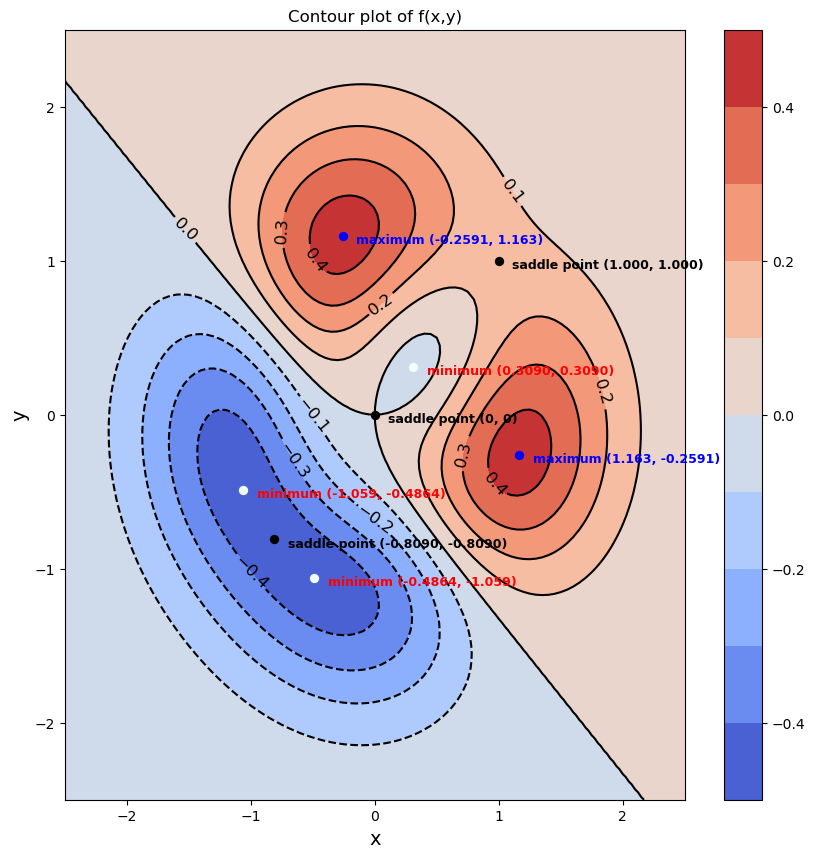

In [153]:
#CONTOUR PLOT OF f(x,y)

#defining points in x and y directions
xp = np.arange(-2.5, 2.55, 0.05)
yp = np.arange(-2.5,2.55,0.05)

#making grid of points
X,Y = np.meshgrid(xp,yp)

#defining function
Z=f2(X,Y)

#figure and subplot initialization
fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(111)

#plotting contours
B = ax.contour(X,Y,Z, levels=10, colors='k')

#drawing labels
ax.clabel(B, fontsize=12)
ax.set_xlabel('x', fontsize=14)
ax.set_ylabel('y', fontsize=14)
ax.set_title("Contour plot of f(x,y)")

#filling contour plot 
C = ax.contourf(X,Y,Z, levels=10, cmap = plt.cm.coolwarm)
fig.colorbar(C)

#marking stationary points and indicating their natures
for a,b,c in SOLS1_TYPES:
    if c == 'saddle':
        ax.scatter(a, b, marker=".", color='black', s=130, zorder=2)
        ax.text(a+0.11, b-0.05, f'saddle point ({a}, {b})', color='black', fontsize=9, fontweight='bold')
    if c == 'minimum':
        ax.scatter(a, b, marker=".", color='azure', s=130, zorder=2)
        ax.text(a+0.11, b-0.05, f'minimum ({a}, {b})', color='red', fontsize=9, fontweight='bold')
    if c == 'maximum':
        ax.scatter(a, b, marker=".", color='b', s=130, zorder=2)
        ax.text(a+0.11, b-0.05, f'maximum ({a}, {b})', color='b', fontsize=9, fontweight='bold')

### Question 6

Still considering the function $f(x,y)$ given above, the aim of this question is to identify all maxima and minima of $f$ subject to a given constraint. We have looked at similar problems in class using the technique of Lagrange Multipliers.


(a) Use Python to locate all maxima and minima of $f$ subject to the constraint 

$$x^2+y^2=2.$$ 

There are a few different ways you could approach this problem and the method is up to you, but you should explain your work. Store your results in a list called `SOLS2_TYPES` where each entry has format `[x,y,'type']` (e.g. `[5,-7,'minimum']` if the location $(5,-7)$ was a minimum along the constraint).

If results are given numerically, they should be accurate to at least $4$ significant figures.

(b) Now make a contour plot of $f(x,y)$ and overlay the constraint. Add markers indicating the locations of each of the extrema of $f(x,y)$ along the constraint, and indicate whether each one is a maximum or minimum point.

<p style='text-align:right;'> <b> [7 Marks] </b> </p>

In [150]:
lam = sym.symbols('lambda', real=True)
#defining the function g(x,y) = constraint
g = x**2 + y**2 - 2
#translating the SymPy expression into a Python function 
g2 = sym.lambdify([x,y], f, 'numpy')

#defining F(x,y,lam)
F= f - lam*g
Fx = sym.diff(F,x)
Fy = sym.diff(F,y)
Flam = sym.diff(F,lam)

results2 = list((sym.nonlinsolve([Fx, Fy, Flam], [x,y,lam]) & (sym.Reals ** 3)).args)
SOLS2=[]
for a,b,c in results2:
    SOLS2.append((a.evalf(4),b.evalf(4)))

SOLS2_TYPES = []
for x0,y0 in SOLS2:
    stationary_type=''
    print(f'f({x0}, {y0}) =', f.evalf(subs={x:x0, y:y0}))


SOLS2_TYPES.append([1.000,1.000, 'minimum'])
SOLS2_TYPES.append([-1.000,-1.000, 'maximum'])
SOLS2_TYPES.append([-0.2688, 1.388, 'maximum'])
SOLS2_TYPES.append([-1.343, -0.4434, 'minimum'])
SOLS2_TYPES.append([1.388, -0.2688, 'maximum'])
SOLS2_TYPES.append([-0.4434, -1.343, 'minimum'])

print(SOLS2_TYPES)

f(1.000, 1.000) = 0.135335283236613
f(-1.000, -1.000) = -0.406005849709838
f(-0.2688, 1.388) = 0.410113218891637
f(-0.2688, 1.388) = 0.410113218891637
f(-1.343, -0.4434) = -0.420135765198863
f(-1.343, -0.4434) = -0.420135765198863
f(1.388, -0.2688) = 0.410113218891637
f(1.388, -0.2688) = 0.410113218891637
f(-0.4434, -1.343) = -0.420135765198863
f(-0.4434, -1.343) = -0.420135765198863
[[1.0, 1.0, 'minimum'], [-1.0, -1.0, 'maximum'], [-0.2688, 1.388, 'maximum'], [-1.343, -0.4434, 'minimum'], [1.388, -0.2688, 'maximum'], [-0.4434, -1.343, 'minimum']]


To obtain all maxima and minima of the function f subject to the constraint x^2 + y^2 = 2 I have used Lagrange multipliers (in the above cell).

I defined the functions g(x,y) as g = x^2 + y^2 -2 = 0 which is the constraint function and F(x,y,lam) where lam is lambda (the Lagrange multiplier) as F = f - lam x g.
I then found the stationary points of F by keeping the real solutions correct to 4 d.p. of Fx = Fy = Flam = 0.

Unfortunately we cannot evaluate delta at these points to determine which are maximum or minimum since they are not stationary points of the function f(x,y) but of F(x,y,lam).
Therefore, I simply printed out the values of f(x,y) evaluated at these points and guessed if these are minima or maxima by looking at how f(x,y) changes as we move away from these points in every direction subject to the constraint.

To visualize this: if we go along the circle given by the constraint, as we follow the function f we go up and down therefore it is easy to guess if the S.P. of F is a local maxima or minima by going along the circle. Each time we go down in value and go back up we have a minima, while when we go up and then go back down we have a maxima.

Finally, I added my results in the required format in a list called SOLS2_TYPES.

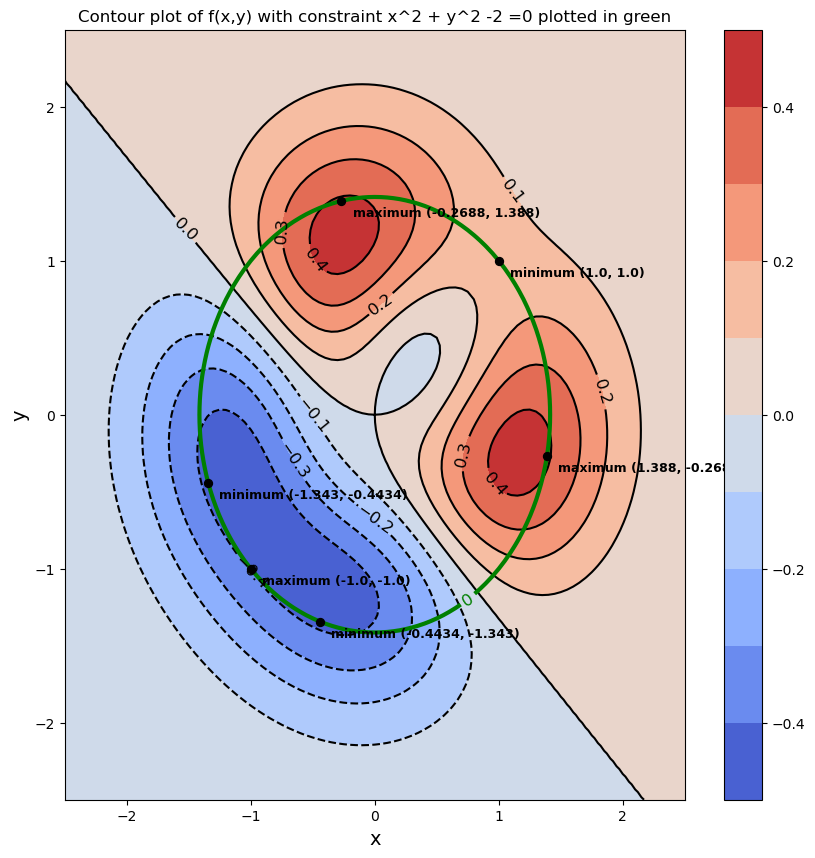

In [151]:
#CONTOUR PLOT OF f(x,y)

#defining points in x and y directions
xp = np.arange(-2.5, 2.55, 0.05)
yp = np.arange(-2.5,2.55,0.05)

#making grid of points
X,Y = np.meshgrid(xp,yp)

#defining functions
Z=f2(X,Y)

#figure and subplot initialization
fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(111)

#plotting contours
B = ax.contour(X,Y,Z, levels=10, colors='k')

#plotting constraint
D = ax.contour(X, Y, X**2 + Y**2 -2, [0], colors='g', linewidths=3)

#drawing labels
ax.clabel(B, fontsize=12)
ax.clabel(D, fontsize=12)
ax.set_xlabel('x', fontsize=14)
ax.set_ylabel('y', fontsize=14)
ax.set_title("Contour plot of f(x,y) with constraint x^2 + y^2 -2 =0 plotted in green")

#filling contour plot
C = ax.contourf(X,Y,Z, levels=10, cmap = plt.cm.coolwarm)
fig.colorbar(C)

#marking stationary points and indicating their natures
for i in SOLS2_TYPES:
    ax.text(i[0]+0.09, i[1]-0.1, f'{i[2]} ({i[0]}, {i[1]})', color='black', fontsize=9, fontweight='bold')
    ax.scatter(i[0], i[1], marker=".", color='black', s=130, zorder=2)

In [152]:
# VALIDATION CELL
from unittest import TestCase
import sympy as sym
nbg_tc = TestCase()

# SOLS2_TYPES should be defined
if not 'SOLS2_TYPES' in globals():
    raise NotImplementedError("SOLS2_TYPES has not been defined in Question 7")

# SOLS2_TYPES should be a list
nbg_tc.assertIsInstance(SOLS2_TYPES, list,
                        msg = f"SOLS2_TYPES should be a list, not a {type(SOLS2_TYPES).__name__}")

# SOLS2_TYPES should not be empty
assert len(SOLS2_TYPES) > 0, "SOLS2_TYPES is empty"

# the entries of SOLS2_TYPES should be lists of length 3
for nbg_sol in SOLS2_TYPES:
    nbg_tc.assertIsInstance(nbg_sol, list, 
                            msg = "each entry of SOLS2_TYPES should be a list")
    nbg_tc.assertEqual(len(nbg_sol), 3,
                       msg = "each entry of SOLS2_TYPES should have length 3")

    # The third value in each entry should be one of "minimum" or "maximum"
    nbg_tc.assertIn(nbg_sol[2].lower(),
                    ["maximum", "minimum"],
                    f"{nbg_sol[2]} should be one of 'maximum' or 'minimum'")
